# Driving Datasets: What KITTI Really Contains, and How to Specify Data for Safety

**Module 01 · Perception and Prediction** · Notebook 8 of 9

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/01_Perception/08_driving_datasets.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [04 Object detection](04_object_detection.ipynb); [05 VRU detection](05_vulnerable_road_user_detection.ipynb) | ISO/PAS 8800:2024; ISO 21448:2022; ISO 34503:2023 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Read dataset statistics critically: scenes vs sensor frames vs annotated keyframes vs boxes, sensors, licences
2. Analyse all 51,865 KITTI object labels: class imbalance, long tail, distance, occlusion, truncation and objects per frame
3. Identify what a dataset does **not** contain (night, rain, distant VRUs) and quantify how many samples a recall claim would need
4. Compare KITTI with nuScenes, Waymo Open, Argoverse 2 and ONCE using published, verified figures
5. Decide whether a dataset licence allows industrial use
6. Write a dataset specification entry that feeds an ISO/PAS 8800 / ISO 21448 safety argument

## Setup

The labels of the whole KITTI object-detection training set are a 5 MB download; images are fetched one at a time (about 1–2 s each) and cached.

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D

In [2]:
import os, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from IPython.display import display

OKABE_ITO = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
VRU = ['Pedestrian', 'Person_sitting', 'Cyclist']
print(f"NumPy {np.__version__}, pandas {pd.__version__}")

NumPy 2.5.4, pandas 3.1.0


### Data and licence

All statistics in Sections 2–4 are computed from the **KITTI object-detection training labels** (7,481 images). KITTI is licensed **CC BY-NC-SA 3.0 — non-commercial**; Section 7 explains what this means for industrial use.

In [3]:
print(D.attribution('KITTI'))
try:
    labels = D.kitti_object_labels_all()
except D.DataUnavailable as exc:
    raise SystemExit(f"KITTI labels unavailable ({exc}); this notebook needs one 5 MB download.")
objs = labels[labels['type'] != 'DontCare'].copy()
dontcare = labels[labels['type'] == 'DontCare']
print(f"{len(labels):,} label lines in {labels['frame'].nunique():,} frames: "
      f"{len(objs):,} objects + {len(dontcare):,} DontCare regions")

Data: KITTI Vision Benchmark Suite (Geiger et al., CVPR 2012 / IJRR 2013), CC BY-NC-SA 3.0, https://www.cvlibs.net/datasets/kitti/


51,865 label lines in 7,481 frames: 40,570 objects + 11,295 DontCare regions


---
## 1. Counting what a dataset contains

Dataset papers report different units. Before comparing numbers, check which one is meant:

| Unit | Meaning | Example |
|---|---|---|
| Scene / sequence / segment | A continuous recording, typically 15–20 s | nuScenes: 1,000 scenes of 20 s |
| Sensor frame | One capture of one sensor (10–20 Hz) | nuScenes: 1.4 M camera images |
| Annotated keyframe | A frame with labels (often sub-sampled, e.g. 2 Hz) | nuScenes: 40 k keyframes |
| Box / instance | One labelled object in one frame | nuScenes: 1.4 M 3D boxes |
| Track | One object followed over time | relevant for tracking and prediction |

The same physical pedestrian seen in 40 consecutive keyframes is 40 boxes but **one** person: box counts overstate the diversity of a dataset. KITTI's object set is a sample of single frames from 6 hours of recordings made on five days in September–October 2011, during daytime, in and around Karlsruhe (Geiger et al., 2013).

---
## 2. KITTI in numbers: class imbalance and the long tail

KITTI annotates eight classes plus `DontCare` (regions with objects that were too far or too small to label). The benchmark evaluates only **Car, Pedestrian and Cyclist**; `Van` and `Person_sitting` are treated as "neighbouring" classes that are neither rewarded nor penalised.

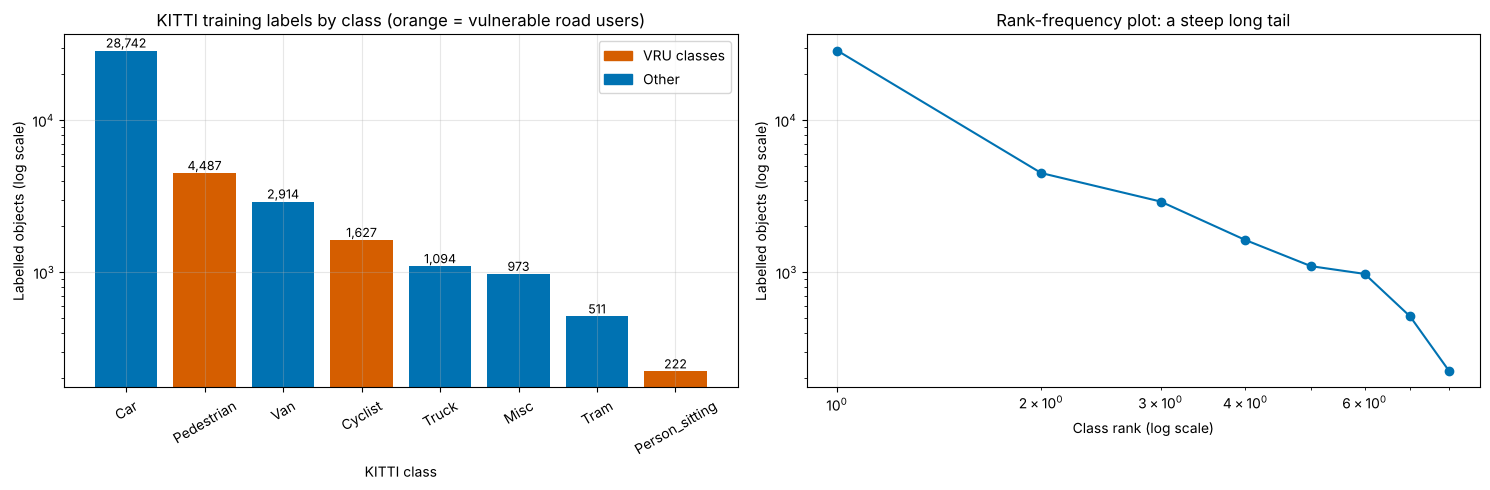

--- KITTI class distribution (computed from all labels) ---
  Car             28,742  (70.85 %)
  Pedestrian       4,487  (11.06 %)
  Van              2,914  ( 7.18 %)
  Cyclist          1,627  ( 4.01 %)
  Truck            1,094  ( 2.70 %)
  Misc               973  ( 2.40 %)
  Tram               511  ( 1.26 %)
  Person_sitting     222  ( 0.55 %)
Imbalance: Car : Person_sitting = 129 : 1; VRU classes together: 15.6 % of objects.


In [4]:
counts = objs['type'].value_counts()
share = counts / counts.sum()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cols = [OKABE_ITO[5] if c in VRU else OKABE_ITO[4] for c in counts.index]
axes[0].bar(counts.index, counts.values, color=cols)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha='center', va='bottom', fontsize=9)
axes[0].set_yscale('log'); axes[0].set_ylabel('Labelled objects (log scale)'); axes[0].set_xlabel('KITTI class')
axes[0].set_title('KITTI training labels by class (orange = vulnerable road users)')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(handles=[Patch(color=OKABE_ITO[5], label='VRU classes'), Patch(color=OKABE_ITO[4], label='Other')])
axes[1].plot(np.arange(1, len(counts) + 1), counts.values, 'o-', color=OKABE_ITO[4])
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('Class rank (log scale)'); axes[1].set_ylabel('Labelled objects (log scale)')
axes[1].set_title('Rank-frequency plot: a steep long tail')
plt.tight_layout(); plt.show()

print("--- KITTI class distribution (computed from all labels) ---")
for c, n in counts.items():
    print(f"  {c:15s} {n:6,}  ({100 * share[c]:5.2f} %)")
print(f"Imbalance: {counts.index[0]} : {counts.index[-1]} = {counts.iloc[0] / counts.iloc[-1]:.0f} : 1; "
      f"VRU classes together: {100 * share[VRU].sum():.1f} % of objects.")

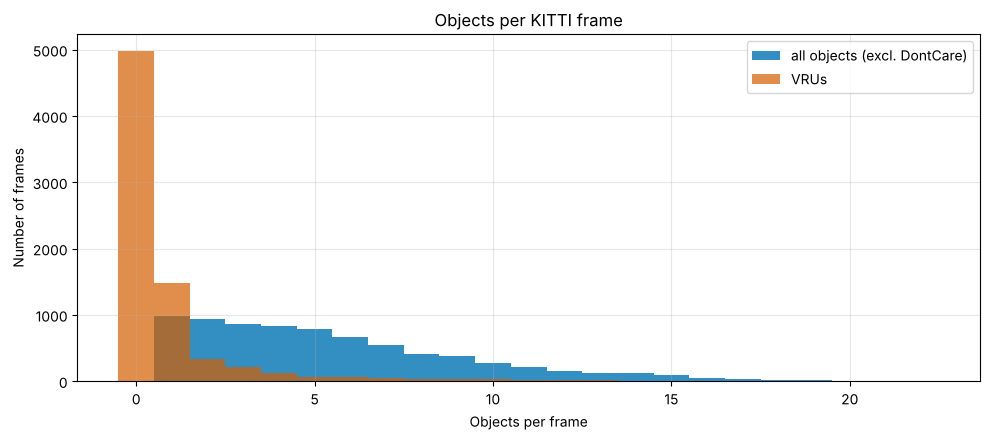

Objects per frame: mean 5.42, median 5, max 22.
Frames with at least one VRU: 2,501 of 7,481 (33.4 %); frames with >= 5 VRUs: 362.


In [5]:
per_frame = objs.groupby('frame').size().reindex(labels['frame'].unique(), fill_value=0)
vru_per_frame = objs[objs['type'].isin(VRU)].groupby('frame').size().reindex(per_frame.index, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.arange(0, per_frame.max() + 2) - 0.5
ax.hist(per_frame, bins=bins, color=OKABE_ITO[4], alpha=0.8, label='all objects (excl. DontCare)')
ax.hist(vru_per_frame, bins=bins, color=OKABE_ITO[5], alpha=0.7, label='VRUs')
ax.set_xlabel('Objects per frame'); ax.set_ylabel('Number of frames'); ax.legend()
ax.set_title('Objects per KITTI frame')
plt.tight_layout(); plt.show()
print(f"Objects per frame: mean {per_frame.mean():.2f}, median {per_frame.median():.0f}, max {per_frame.max()}.")
print(f"Frames with at least one VRU: {(vru_per_frame > 0).sum():,} of {len(per_frame):,} "
      f"({100 * (vru_per_frame > 0).mean():.1f} %); frames with >= 5 VRUs: {(vru_per_frame >= 5).sum():,}.")

### Real KITTI frames with their labels

Two training frames with every label line drawn: evaluated classes in colour, `DontCare` regions hatched. Note how small the distant objects are and how many of them are not labelled individually.

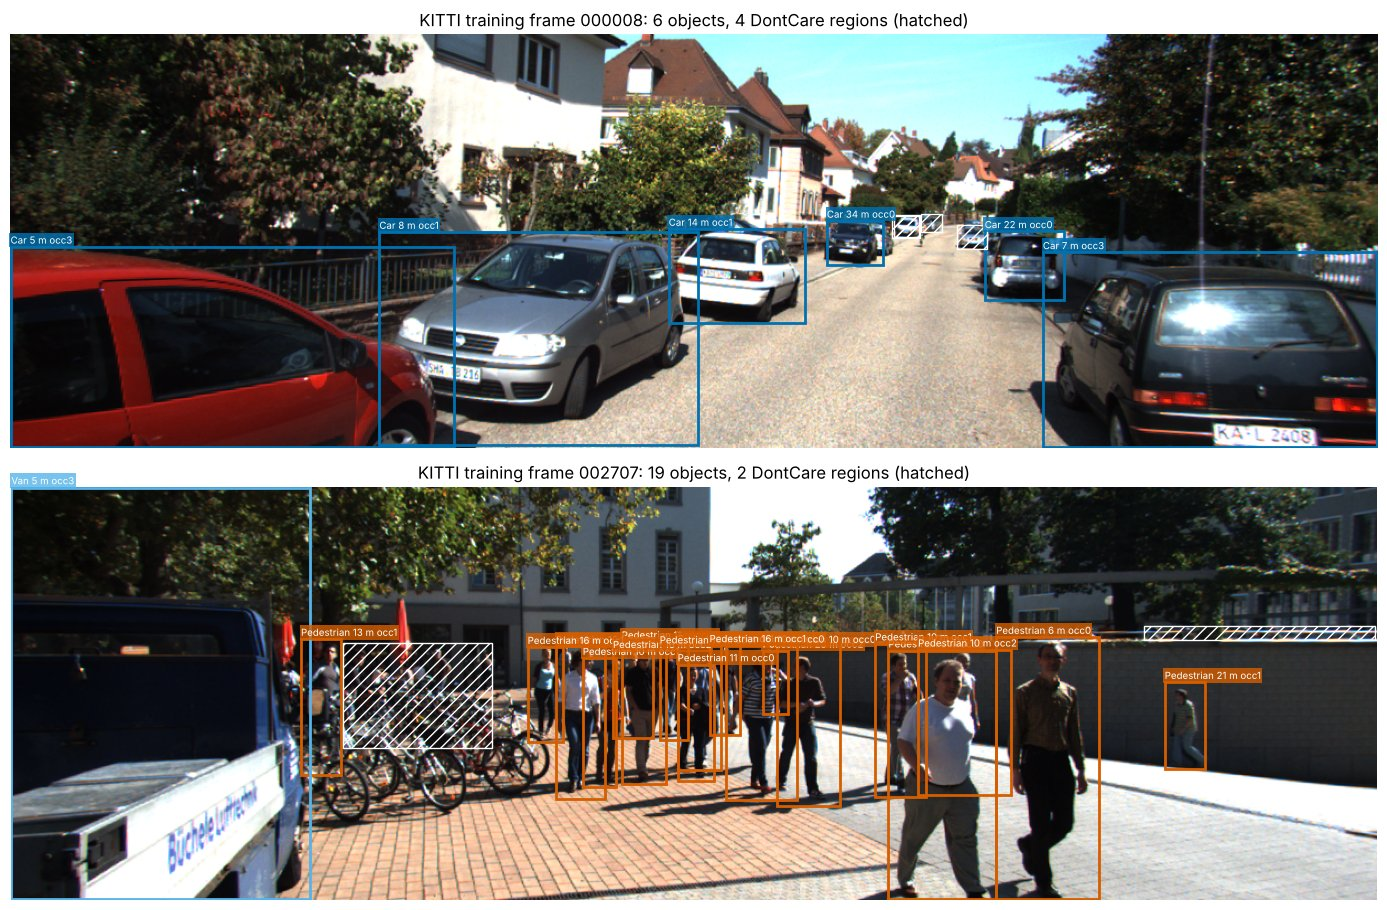

Data: KITTI Vision Benchmark Suite (Geiger et al., CVPR 2012 / IJRR 2013), CC BY-NC-SA 3.0, https://www.cvlibs.net/datasets/kitti/


In [6]:
SHOW_FRAMES = [8, int(vru_per_frame.idxmax())]   # a street scene, and the frame with the most VRUs
COL = {'Car': OKABE_ITO[4], 'Van': OKABE_ITO[1], 'Truck': OKABE_ITO[1], 'Pedestrian': OKABE_ITO[5],
       'Person_sitting': OKABE_ITO[6], 'Cyclist': OKABE_ITO[0], 'Tram': OKABE_ITO[2], 'Misc': OKABE_ITO[2]}
fig, axes = plt.subplots(len(SHOW_FRAMES), 1, figsize=(15, 4.6 * len(SHOW_FRAMES)))
for ax, idx in zip(axes, SHOW_FRAMES):
    fr = D.kitti_object(idx, parts=('image', 'labels'))
    ax.imshow(fr.image); ax.axis('off')
    for l in fr.labels:
        x1, y1, x2, y2 = l['x1'], l['y1'], l['x2'], l['y2']
        if l['type'] == 'DontCare':
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, hatch='///', lw=1, edgecolor='white'))
            continue
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=2, edgecolor=COL[l['type']]))
        ax.text(x1, y1 - 3, f"{l['type']} {np.hypot(l['x'], l['z']):.0f} m occ{l['occluded']}",
                color='white', fontsize=7, bbox=dict(facecolor=COL[l['type']], alpha=0.8, pad=1, edgecolor='none'))
    n_dc = sum(l['type'] == 'DontCare' for l in fr.labels)
    ax.set_title(f"KITTI training frame {idx:06d}: {len(fr.labels) - n_dc} objects, {n_dc} DontCare regions (hatched)")
plt.tight_layout(); plt.show()
print(D.attribution('KITTI'))

---
## 3. Distance, size, occlusion and truncation

KITTI labels include each object's 3D position in camera coordinates, so the distance $\sqrt{x^2 + z^2}$ is known for every object. The image height of an object follows the pinhole model, $h_{px} \approx f\,H / Z$ with focal length $f$ (about 720 px for KITTI's colour cameras), real height $H$ and depth $Z$. The benchmark's difficulty levels are defined on **pixel height, occlusion and truncation** — not on distance.

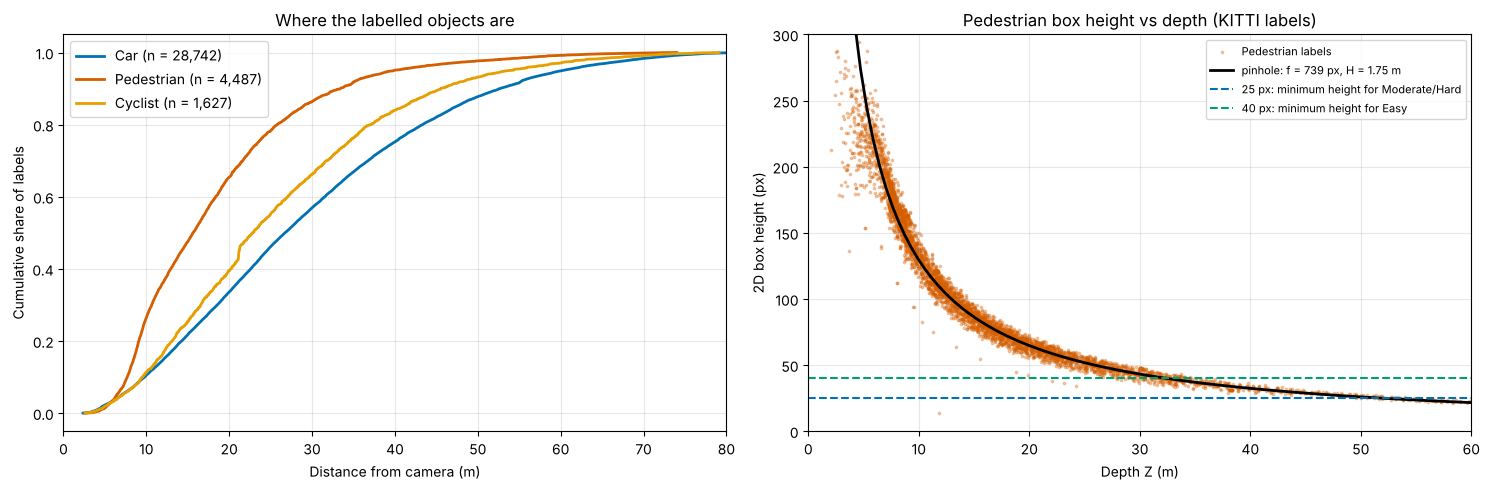

Focal length estimated from the labels: 739 px.
A 1.75 m pedestrian falls below 40 px beyond 32 m and below 25 px beyond 52 m -> beyond ~52 m KITTI does not evaluate pedestrians at all.
  Car       : median 26.7 m, 90th percentile 52.6 m, beyond 40 m: 7,118 (24.8 %)
  Pedestrian: median 15.6 m, 90th percentile 33.4 m, beyond 40 m:   220 (4.9 %)
  Cyclist   : median 22.8 m, 90th percentile 45.5 m, beyond 40 m:   261 (16.0 %)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for c, col in [('Car', OKABE_ITO[4]), ('Pedestrian', OKABE_ITO[5]), ('Cyclist', OKABE_ITO[0])]:
    d = np.sort(objs.loc[objs['type'] == c, 'distance_m'].to_numpy())
    axes[0].plot(d, np.arange(1, len(d) + 1) / len(d), color=col, lw=2, label=f"{c} (n = {len(d):,})")
axes[0].set_xlabel('Distance from camera (m)'); axes[0].set_ylabel('Cumulative share of labels')
axes[0].set_title('Where the labelled objects are'); axes[0].set_xlim(0, 80); axes[0].legend()

ped = objs[objs['type'] == 'Pedestrian']
axes[1].scatter(ped['z'], ped['box_height_px'], s=3, alpha=0.3, color=OKABE_ITO[5], label='Pedestrian labels')
Z = ped['z'].to_numpy(); Hm = ped['h'].to_numpy(); hp = ped['box_height_px'].to_numpy()
ok = (Z > 3) & (ped['truncated'].to_numpy() < 0.1) & (ped['occluded'].to_numpy() == 0)
f_est = float(np.median(hp[ok] * Z[ok] / Hm[ok]))                 # focal length estimated from the labels
zz = np.linspace(3, 60, 100)
axes[1].plot(zz, f_est * 1.75 / zz, color='black', lw=2, label=f"pinhole: f = {f_est:.0f} px, H = 1.75 m")
axes[1].axhline(25, color=OKABE_ITO[4], ls='--', label='25 px: minimum height for Moderate/Hard')
axes[1].axhline(40, color=OKABE_ITO[2], ls='--', label='40 px: minimum height for Easy')
axes[1].set_xlim(0, 60); axes[1].set_ylim(0, 300)
axes[1].set_xlabel('Depth Z (m)'); axes[1].set_ylabel('2D box height (px)')
axes[1].set_title('Pedestrian box height vs depth (KITTI labels)'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

z25, z40 = f_est * 1.75 / 25, f_est * 1.75 / 40
print(f"Focal length estimated from the labels: {f_est:.0f} px.")
print(f"A 1.75 m pedestrian falls below 40 px beyond {z40:.0f} m and below 25 px beyond {z25:.0f} m "
      f"-> beyond ~{z25:.0f} m KITTI does not evaluate pedestrians at all.")
for c in ['Car', 'Pedestrian', 'Cyclist']:
    d = objs.loc[objs['type'] == c, 'distance_m']
    print(f"  {c:10s}: median {d.median():4.1f} m, 90th percentile {d.quantile(0.9):4.1f} m, "
          f"beyond 40 m: {(d > 40).sum():5,} ({100 * (d > 40).mean():.1f} %)")

**A step in the cyclist curve.** The cumulative distance curve for cyclists jumps at about 21 m. The cause is not physics but sampling: KITTI's object frames were drawn from recordings, and while the ego vehicle stood still the same cyclist was captured in many frames with almost identical labels. The cell below finds such repeats (same class, 3D position within 0.25 m and box corners within 4 px).

In [8]:
key = pd.DataFrame({'type': objs['type'], 'x': (objs['x'] / 0.25).round(), 'z': (objs['z'] / 0.25).round(),
                    'u1': (objs['x1'] / 4).round(), 'v1': (objs['y1'] / 4).round(), 'u2': (objs['x2'] / 4).round()})
repeats = objs.assign(k=pd.util.hash_pandas_object(key, index=False)).groupby(['type', 'k'])['frame'].nunique()
rows = []
for c in ['Car', 'Pedestrian', 'Cyclist']:
    r = repeats.loc[c]
    rows.append({'class': c, 'labels': int(r.sum()), 'objects seen in >= 5 frames': int((r >= 5).sum()),
                 'labels belonging to them': int(r[r >= 5].sum()), 'largest repeat (frames)': int(r.max())})
rep_df = pd.DataFrame(rows).set_index('class'); display(rep_df)
cy = rep_df.loc['Cyclist']
print(f"Cyclists: {cy['labels belonging to them']} labels ({100 * cy['labels belonging to them'] / cy['labels']:.1f} %) "
      f"come from {cy['objects seen in >= 5 frames']} near-identical objects; one appears in {cy['largest repeat (frames)']} frames.")
print("Frame counts overstate the number of independent samples: split train/test by recording, not by frame.")

,labels,objects seen in >= 5 frames,labels belonging to them,largest repeat (frames)
class,,,,
Car,28742,55,614,51
Pedestrian,4487,1,5,5
Cyclist,1627,2,50,28


Cyclists: 50 labels (3.1 %) come from 2 near-identical objects; one appears in 28 frames.
Frame counts overstate the number of independent samples: split train/test by recording, not by frame.


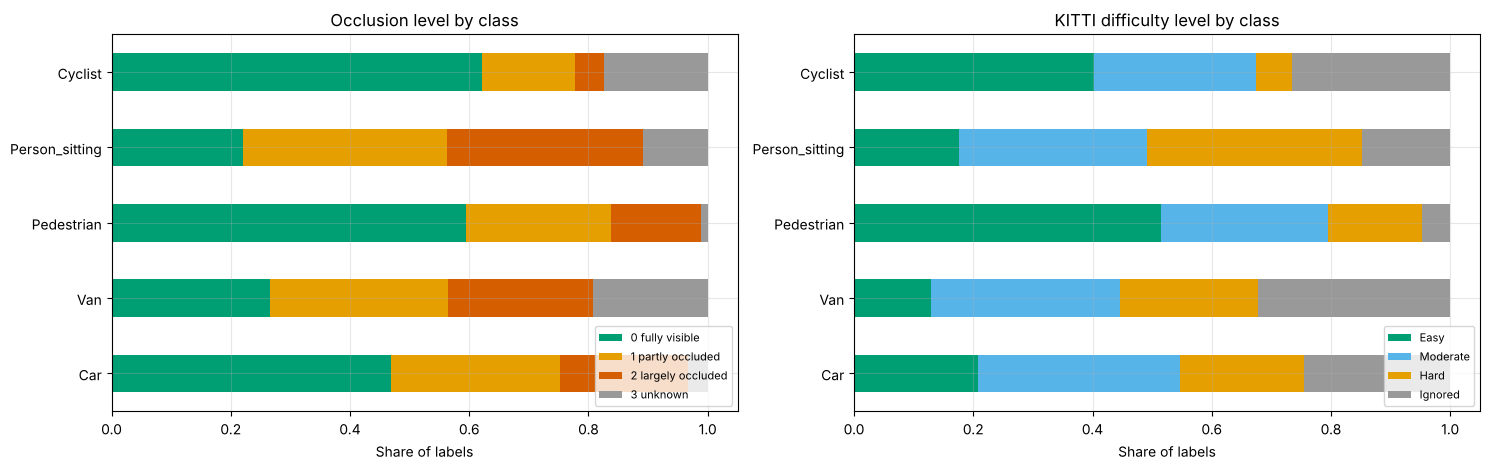

difficulty,Easy,Moderate,Hard,Ignored
type,,,,
Car,5971,9739,6006,7026
Van,378,920,675,941
Pedestrian,2310,1259,707,211
Person_sitting,39,70,80,33
Cyclist,654,444,96,433


Truncation share by class:


t,0,0-0.15,0.15-0.3,0.3-0.5,> 0.5
type,,,,,
Car,0.858,0.021,0.017,0.021,0.082
Van,0.849,0.020,0.017,0.020,0.095
Pedestrian,0.917,0.032,0.018,0.013,0.020
Person_sitting,0.752,0.059,0.045,0.063,0.081
Cyclist,0.918,0.015,0.015,0.011,0.042


  Car            : 46.8 % fully visible, 24.4 % never evaluated ('Ignored')
  Van            : 26.6 % fully visible, 32.3 % never evaluated ('Ignored')
  Pedestrian     : 59.4 % fully visible,  4.7 % never evaluated ('Ignored')
  Person_sitting : 22.1 % fully visible, 14.9 % never evaluated ('Ignored')
  Cyclist        : 62.1 % fully visible, 26.6 % never evaluated ('Ignored')
DontCare regions: 11,295, median height 20 px - unlabelled objects that a detector may legitimately detect.


In [9]:
occ_names = {0: '0 fully visible', 1: '1 partly occluded', 2: '2 largely occluded', 3: '3 unknown'}
classes = ['Car', 'Van', 'Pedestrian', 'Person_sitting', 'Cyclist']
occ = pd.crosstab(objs['type'], objs['occluded'], normalize='index').loc[classes].rename(columns=occ_names)
trunc = objs.assign(t=pd.cut(objs['truncated'], [-0.01, 0.0, 0.15, 0.3, 0.5, 1.0],
                             labels=['0', '0-0.15', '0.15-0.3', '0.3-0.5', '> 0.5']))
trunc = pd.crosstab(trunc['type'], trunc['t'], normalize='index').loc[classes]
diff = pd.crosstab(objs['type'], objs['difficulty']).loc[classes, ['Easy', 'Moderate', 'Hard', 'Ignored']]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
occ.plot(kind='barh', stacked=True, ax=axes[0], color=[OKABE_ITO[2], OKABE_ITO[0], OKABE_ITO[5], '#999999'])
axes[0].set_xlabel('Share of labels'); axes[0].set_ylabel(''); axes[0].set_title('Occlusion level by class')
axes[0].legend(fontsize=8, loc='lower right')
(diff.div(diff.sum(axis=1), axis=0)).plot(kind='barh', stacked=True, ax=axes[1],
                                     color=[OKABE_ITO[2], OKABE_ITO[1], OKABE_ITO[0], '#999999'])
axes[1].set_xlabel('Share of labels'); axes[1].set_ylabel(''); axes[1].set_title('KITTI difficulty level by class')
axes[1].legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()
display(diff)
print("Truncation share by class:"); display(trunc.round(3))
for c in classes:
    print(f"  {c:15s}: {100 * occ.loc[c].iloc[0]:4.1f} % fully visible, "
          f"{100 * diff.loc[c, 'Ignored'] / diff.loc[c].sum():4.1f} % never evaluated ('Ignored')")
print(f"DontCare regions: {len(dontcare):,}, median height {dontcare['box_height_px'].median():.0f} px "
      "- unlabelled objects that a detector may legitimately detect.")

**Reading the numbers.** About a quarter of all cars and cyclists are never scored by the benchmark (`Ignored`: too small, too occluded or too truncated; pedestrians are closer to the camera, so only about 5 % of them), and `DontCare` regions hide thousands of further objects. A model can therefore look excellent on KITTI while having been measured only on the comfortable part of the distribution. Cyclists with occlusion level 3 ("unknown") are a reminder that label quality itself is a dataset property that must be specified and checked.

---
## 4. What is missing, and how many samples a claim would need

KITTI has no weather or light attribute because it does not need one: every frame is daytime in and around Karlsruhe. For a safety argument the question is not "is the dataset big?" but "does it contain enough examples **of each relevant condition** to support the claim I want to make?"

A simple, conservative rule: to claim a per-instance recall of at least $R$ with confidence $C$ from a test in which **no** instance is missed, you need $n \ge \ln(1-C)/\ln R$ independent instances (binomial zero-failure argument). For $R = 0.99$ and $C = 0.95$ that is 299 instances. Instances from the same track are not independent, so the real requirement is higher.

In [10]:
def n_required(recall, confidence=0.95):
    # Zero-failure binomial sample size: smallest n with recall**n <= 1 - confidence.
    return int(np.ceil(np.log(1 - confidence) / np.log(recall)))

N99 = n_required(0.99)
ped = objs['type'] == 'Pedestrian'; cyc = objs['type'] == 'Cyclist'
cells = {
    'Pedestrian, 0-20 m, fully visible': ped & (objs['distance_m'] <= 20) & (objs['occluded'] == 0),
    'Pedestrian, 30-50 m': ped & objs['distance_m'].between(30, 50),
    'Pedestrian, > 40 m': ped & (objs['distance_m'] > 40),
    'Pedestrian, largely occluded (occ 2)': ped & (objs['occluded'] == 2),
    'Cyclist, > 30 m': cyc & (objs['distance_m'] > 30),
    'Cyclist, partly/largely occluded': cyc & objs['occluded'].isin([1, 2]),
    'Person_sitting (all)': objs['type'] == 'Person_sitting',
    'Any VRU at night': pd.Series(False, index=objs.index),
    'Any VRU in rain, fog or snow': pd.Series(False, index=objs.index),
    'Child / wheelchair / e-scooter (no label)': pd.Series(False, index=objs.index),
}
gap = pd.DataFrame({'labelled instances': {k: int(m.sum()) for k, m in cells.items()},
                    'distinct frames': {k: objs.loc[m, 'frame'].nunique() for k, m in cells.items()}})
gap['>= 299 instances?'] = np.where(gap['labelled instances'] >= N99, 'yes', 'NO')
display(gap)
print(f"Instances needed to claim recall >= 0.99 with 95 % confidence and zero misses: {N99} "
      f"(recall >= 0.999: {n_required(0.999)}).")
short = gap.index[gap['labelled instances'] < N99].tolist()
print(f"{len(short)} of {len(gap)} safety-relevant cells cannot support even the 0.99 claim on KITTI alone:")
for k in short:
    print(f"  - {k}: {gap.loc[k, 'labelled instances']} instances")

,labelled instances,distinct frames,>= 299 instances?
"Pedestrian, 0-20 m, fully visible",1892,1036,yes
"Pedestrian, 30-50 m",506,336,yes
"Pedestrian, > 40 m",220,164,NO
"Pedestrian, largely occluded (occ 2)",671,451,yes
"Cyclist, > 30 m",550,440,yes
"Cyclist, partly/largely occluded",335,297,yes
Person_sitting (all),222,99,NO
Any VRU at night,0,0,NO
"Any VRU in rain, fog or snow",0,0,NO
Child / wheelchair / e-scooter (no label),0,0,NO


Instances needed to claim recall >= 0.99 with 95 % confidence and zero misses: 299 (recall >= 0.999: 2995).
5 of 10 safety-relevant cells cannot support even the 0.99 claim on KITTI alone:
  - Pedestrian, > 40 m: 220 instances
  - Person_sitting (all): 222 instances
  - Any VRU at night: 0 instances
  - Any VRU in rain, fog or snow: 0 instances
  - Child / wheelchair / e-scooter (no label): 0 instances


**Why this matters for SOTIF and ISO/PAS 8800.** Each empty or thin cell is a candidate **triggering condition** whose effect has not been measured (ISO 21448: a potential "unknown" until analysed), and a gap in the **data specification** in the sense of ISO/PAS 8800 (data must be specified against the input space the AI component will see in its ODD, and the sufficiency of the data must be argued). The remedy is a specification first — which conditions, which classes, which distance bands, how many independent instances — and data collection, simulation or a restricted ODD second.

---
## 5. KITTI compared with later datasets

The figures below are taken from the dataset papers and official websites (checked October 2026). They are not directly comparable — see the units in Section 1.

| Dataset | Recording | Annotated data (as published) | Classes | Sensors | Licence |
|---|---|---|---|---|---|
| **KITTI** object (Geiger et al. 2012, 2013) | Karlsruhe, daytime, 6 h of recordings (2011) | 7,481 training + 7,518 test images; 40,570 labelled training objects (computed above) | 8 + DontCare; 3 evaluated | 2 colour + 2 grey cameras, 1 × 64-beam LiDAR, GPS/IMU | CC BY-NC-SA 3.0 (non-commercial) |
| **nuScenes** (Caesar et al. 2020) | Boston, Singapore; incl. rain and night | 1,000 scenes × 20 s; 40 k keyframes; 1.4 M 3D boxes | 23 classes, 8 attributes; 10 evaluated | 6 cameras, 5 radars, 1 LiDAR (360°) | CC BY-NC-SA 4.0; commercial licence from Motional |
| **Waymo Open – Perception** (Sun et al. 2020; website) | Several US cities | 2,030 segments × 20 s at 10 Hz (390 k frames); 12.6 M 3D and 11.8 M 2D boxes | vehicle, pedestrian, cyclist, sign | 5 cameras, 5 LiDARs | Waymo licence, non-commercial |
| **Argoverse 2 – Sensor** (Wilson et al. 2021) | 6 US cities | 1,000 sequences with 3D cuboids | 26 categories | 7 ring + 2 stereo cameras, 2 LiDARs | CC BY-NC-SA 4.0 (non-commercial) |
| **ONCE** (Mao et al. 2021) | China, 144 driving hours | 1 M LiDAR scenes, 7 M images; 15 k fully annotated scenes | 5 (car, bus, truck, pedestrian, cyclist) | cameras, 1 LiDAR | CC BY-NC-SA 4.0 + terms; commercial use prohibited |
| **Zenseact Open Dataset** (Alibeigi et al. 2023) | Several European countries, two years | 100 k curated frames, 1,473 sequences, 29 drives; 3D boxes up to 245 m | see paper | cameras, LiDARs, GNSS/IMU | CC BY-SA 4.0 (commercial use permitted under its terms) |

nuScenes alone has about 35 times as many 3D boxes as the KITTI training set; Waymo Open about 300 times. More important for safety: nuScenes, Waymo and ONCE contain night and rain, which KITTI does not.

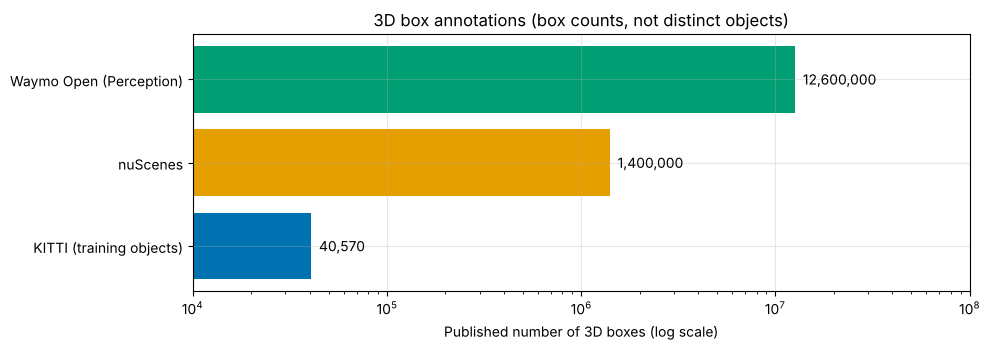

  KITTI (training objects): 40,570 3D boxes (1 x KITTI)
  nuScenes: 1,400,000 3D boxes (35 x KITTI)
  Waymo Open (Perception): 12,600,000 3D boxes (311 x KITTI)
Box counts include the same object in many frames; they are an upper bound on diversity.


In [11]:
boxes_3d = pd.Series({'KITTI (training objects)': len(objs), 'nuScenes': 1.4e6, 'Waymo Open (Perception)': 12.6e6})
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(boxes_3d.index, boxes_3d.values, color=[OKABE_ITO[4], OKABE_ITO[0], OKABE_ITO[2]])
ax.set_xscale('log'); ax.set_xlabel('Published number of 3D boxes (log scale)')
for i, v in enumerate(boxes_3d.values):
    ax.text(v * 1.1, i, f"{v:,.0f}", va='center')
ax.set_xlim(1e4, 1e8); ax.set_title('3D box annotations (box counts, not distinct objects)')
plt.tight_layout(); plt.show()
for k, v in boxes_3d.items():
    print(f"  {k}: {v:,.0f} 3D boxes ({v / len(objs):,.0f} x KITTI)")
print("Box counts include the same object in many frames; they are an upper bound on diversity.")

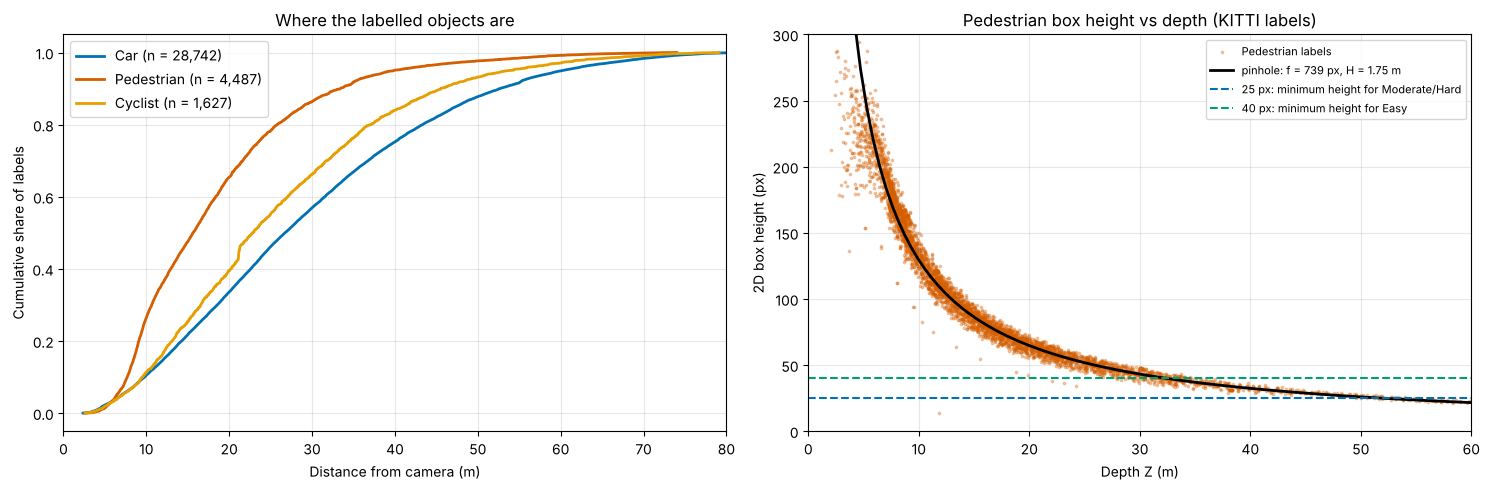

Focal length estimated from the labels: 739 px.
A 1.75 m pedestrian falls below 40 px beyond 32 m and below 25 px beyond 52 m -> beyond ~52 m KITTI does not evaluate pedestrians at all.
  Car       : median 26.7 m, 90th percentile 52.6 m, beyond 40 m: 7,118 (24.8 %)
  Pedestrian: median 15.6 m, 90th percentile 33.4 m, beyond 40 m:   220 (4.9 %)
  Cyclist   : median 22.8 m, 90th percentile 45.5 m, beyond 40 m:   261 (16.0 %)


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for c, col in [('Car', OKABE_ITO[4]), ('Pedestrian', OKABE_ITO[5]), ('Cyclist', OKABE_ITO[0])]:
    d = np.sort(objs.loc[objs['type'] == c, 'distance_m'].to_numpy())
    axes[0].plot(d, np.arange(1, len(d) + 1) / len(d), color=col, lw=2, label=f"{c} (n = {len(d):,})")
axes[0].set_xlabel('Distance from camera (m)'); axes[0].set_ylabel('Cumulative share of labels')
axes[0].set_title('Where the labelled objects are'); axes[0].set_xlim(0, 80); axes[0].legend()

ped = objs[objs['type'] == 'Pedestrian']
axes[1].scatter(ped['z'], ped['box_height_px'], s=3, alpha=0.3, color=OKABE_ITO[5], label='Pedestrian labels')
Z = ped['z'].to_numpy(); Hm = ped['h'].to_numpy(); hp = ped['box_height_px'].to_numpy()
ok = (Z > 3) & (ped['truncated'].to_numpy() < 0.1) & (ped['occluded'].to_numpy() == 0)
f_est = float(np.median(hp[ok] * Z[ok] / Hm[ok]))                 # focal length estimated from the labels
zz = np.linspace(3, 60, 100)
axes[1].plot(zz, f_est * 1.75 / zz, color='black', lw=2, label=f"pinhole: f = {f_est:.0f} px, H = 1.75 m")
axes[1].axhline(25, color=OKABE_ITO[4], ls='--', label='25 px: minimum height for Moderate/Hard')
axes[1].axhline(40, color=OKABE_ITO[2], ls='--', label='40 px: minimum height for Easy')
axes[1].set_xlim(0, 60); axes[1].set_ylim(0, 300)
axes[1].set_xlabel('Depth Z (m)'); axes[1].set_ylabel('2D box height (px)')
axes[1].set_title('Pedestrian box height vs depth (KITTI labels)'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

z25, z40 = f_est * 1.75 / 25, f_est * 1.75 / 40
print(f"Focal length estimated from the labels: {f_est:.0f} px.")
print(f"A 1.75 m pedestrian falls below 40 px beyond {z40:.0f} m and below 25 px beyond {z25:.0f} m "
      f"-> beyond ~{z25:.0f} m KITTI does not evaluate pedestrians at all.")
for c in ['Car', 'Pedestrian', 'Cyclist']:
    d = objs.loc[objs['type'] == c, 'distance_m']
    print(f"  {c:10s}: median {d.median():4.1f} m, 90th percentile {d.quantile(0.9):4.1f} m, "
          f"beyond 40 m: {(d > 40).sum():5,} ({100 * (d > 40).mean():.1f} %)")

/tmp/ipykernel_15341/3429558390.py:13: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  (diff.div(diff.sum(1), axis=0)).plot(kind='barh', stacked=True, ax=axes[1],


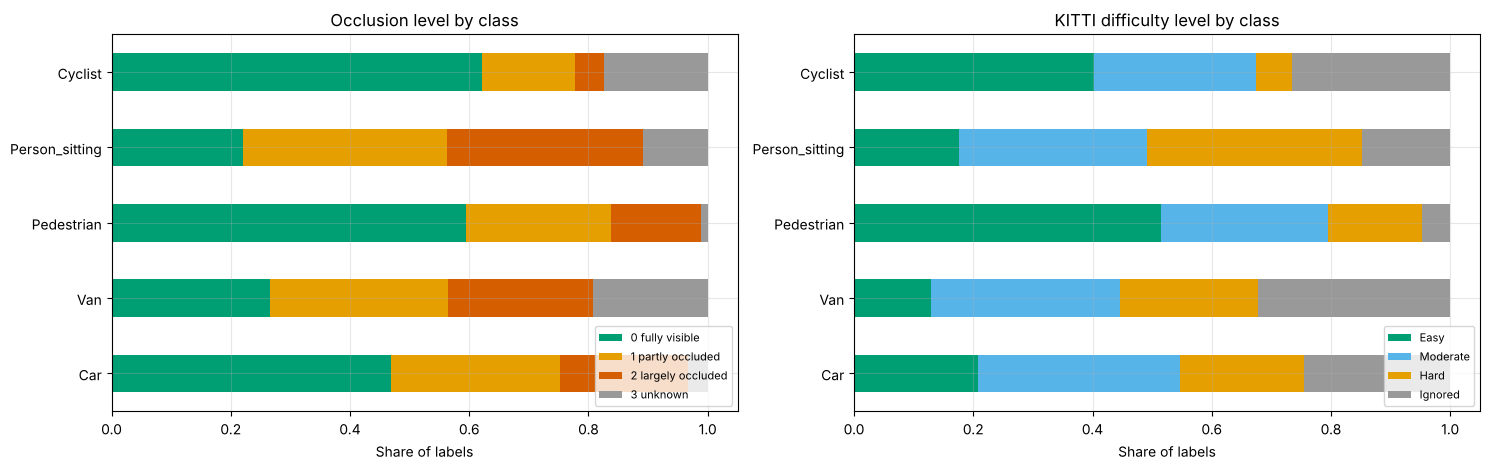

difficulty,Easy,Moderate,Hard,Ignored
type,,,,
Car,5971,9739,6006,7026
Van,378,920,675,941
Pedestrian,2310,1259,707,211
Person_sitting,39,70,80,33
Cyclist,654,444,96,433


Truncation share by class:


t,0,0-0.15,0.15-0.3,0.3-0.5,> 0.5
type,,,,,
Car,0.858,0.021,0.017,0.021,0.082
Van,0.849,0.020,0.017,0.020,0.095
Pedestrian,0.917,0.032,0.018,0.013,0.020
Person_sitting,0.752,0.059,0.045,0.063,0.081
Cyclist,0.918,0.015,0.015,0.011,0.042


  Car            : 46.8 % fully visible, 24.4 % never evaluated ('Ignored')
  Van            : 26.6 % fully visible, 32.3 % never evaluated ('Ignored')
  Pedestrian     : 59.4 % fully visible,  4.7 % never evaluated ('Ignored')
  Person_sitting : 22.1 % fully visible, 14.9 % never evaluated ('Ignored')
  Cyclist        : 62.1 % fully visible, 26.6 % never evaluated ('Ignored')
DontCare regions: 11,295, median height 20 px - unlabelled objects that a detector may legitimately detect.


In [13]:
occ_names = {0: '0 fully visible', 1: '1 partly occluded', 2: '2 largely occluded', 3: '3 unknown'}
classes = ['Car', 'Van', 'Pedestrian', 'Person_sitting', 'Cyclist']
occ = pd.crosstab(objs['type'], objs['occluded'], normalize='index').loc[classes].rename(columns=occ_names)
trunc = objs.assign(t=pd.cut(objs['truncated'], [-0.01, 0.0, 0.15, 0.3, 0.5, 1.0],
                             labels=['0', '0-0.15', '0.15-0.3', '0.3-0.5', '> 0.5']))
trunc = pd.crosstab(trunc['type'], trunc['t'], normalize='index').loc[classes]
diff = pd.crosstab(objs['type'], objs['difficulty']).loc[classes, ['Easy', 'Moderate', 'Hard', 'Ignored']]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
occ.plot(kind='barh', stacked=True, ax=axes[0], color=[OKABE_ITO[2], OKABE_ITO[0], OKABE_ITO[5], '#999999'])
axes[0].set_xlabel('Share of labels'); axes[0].set_ylabel(''); axes[0].set_title('Occlusion level by class')
axes[0].legend(fontsize=8, loc='lower right')
(diff.div(diff.sum(1), axis=0)).plot(kind='barh', stacked=True, ax=axes[1],
                                     color=[OKABE_ITO[2], OKABE_ITO[1], OKABE_ITO[0], '#999999'])
axes[1].set_xlabel('Share of labels'); axes[1].set_ylabel(''); axes[1].set_title('KITTI difficulty level by class')
axes[1].legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()
display(diff)
print("Truncation share by class:"); display(trunc.round(3))
for c in classes:
    print(f"  {c:15s}: {100 * occ.loc[c].iloc[0]:4.1f} % fully visible, "
          f"{100 * diff.loc[c, 'Ignored'] / diff.loc[c].sum():4.1f} % never evaluated ('Ignored')")
print(f"DontCare regions: {len(dontcare):,}, median height {dontcare['box_height_px'].median():.0f} px "
      "- unlabelled objects that a detector may legitimately detect.")

**Reading the numbers.** A sizeable share of every class is never scored by the benchmark (`Ignored`: too small, too occluded or too truncated), and `DontCare` regions hide thousands of further objects. A model can therefore look excellent on KITTI while having been measured only on the comfortable part of the distribution. Cyclists with occlusion level 3 ("unknown") are a reminder that label quality itself is a dataset property that must be specified and checked.

---
## 7. Licences: can industry use these datasets?

| Dataset | Licence | Training a model for a product? |
|---|---|---|
| KITTI | CC BY-NC-SA 3.0 | **No** — non-commercial only |
| nuScenes | CC BY-NC-SA 4.0 | Only with a separate commercial licence from Motional |
| Waymo Open | Waymo Dataset Licence, non-commercial | **No** |
| Argoverse 2 | CC BY-NC-SA 4.0 | **No** (the terms give exactly this example as prohibited) |
| ONCE | CC BY-NC-SA 4.0 + dataset terms | **No** |
| Zenseact Open Dataset | CC BY-SA 4.0 | Yes, under attribution and share-alike terms (check derivatives) |
| SOTIF-PCOD (Patel 2024) | CC BY 4.0 | Yes, with attribution |

Practical consequences for an engineering team:

- Results obtained on non-commercial data may be **published**, but a model or a parameter tuned on such data must not end up in a product. Keep a data-provenance record for every model.
- Pretrained weights inherit questions about their training data (this course uses COCO-pretrained torchvision weights for teaching only).
- Benchmark data is a reference, not the evidence for a product: the safety case needs data from the product's own sensors and ODD.

*This is engineering guidance, not legal advice; read the current licence text before use.*

---
## 8. SOTIF-PCOD: a LiDAR dataset built around triggering conditions

**SOTIF-PCOD** (Patel, 2024; IEEE DataPort, doi:[10.21227/j43q-z578](https://doi.org/10.21227/j43q-z578), **CC BY 4.0**, about 1.84 GB) is a LiDAR point-cloud dataset generated in the CARLA simulator for a SOTIF-related use case. According to its DataPort record it models **21 weather conditions** (clear, cloudy and rainy at noon, sunset and night) and contains **547 frames** in **KITTI format**, so KITTI tooling (and `avsafety.data.parse_object_labels`) can read it. It was used to evaluate pretrained 3D detectors (MMDetection3D, OpenPCDet) with AP and recall (Patel & Jung, VEHITS 2024).

It complements KITTI exactly where KITTI is empty (night, rain) — at the price of a **simulation-to-reality gap** that must itself be argued. Downloading requires a (free) IEEE DataPort login, so it is not fetched here. If you have it, set `SOTIF_PCOD_DIR` to the extracted folder and run the optional cell.

In [14]:
# Optional: summarise a local copy of SOTIF-PCOD (KITTI format). Skipped if SOTIF_PCOD_DIR is not set.
root = os.environ.get('SOTIF_PCOD_DIR')
if root and Path(root).is_dir():
    bins = sorted(glob.glob(os.path.join(root, '**', '*.bin'), recursive=True))
    txts = [p for p in glob.glob(os.path.join(root, '**', '*.txt'), recursive=True) if 'label' in p.lower()]
    recs = [r for p in txts for r in D.parse_object_labels(Path(p).read_text())]
    print(f"SOTIF-PCOD at {root}: {len(bins)} point clouds, {len(txts)} label files, {len(recs)} objects")
    if recs:
        print(pd.Series([r['type'] for r in recs]).value_counts().to_string())
    if bins:
        pts = np.fromfile(bins[0], dtype=np.float32).reshape(-1, 4)
        print(f"First cloud: {len(pts):,} points, range {np.linalg.norm(pts[:, :3], axis=1).max():.0f} m")
else:
    print("SOTIF-PCOD not found (set SOTIF_PCOD_DIR). Obtain it from IEEE DataPort, doi:10.21227/j43q-z578 "
          "(free account required; CC BY 4.0).")

SOTIF-PCOD not found (set SOTIF_PCOD_DIR). Obtain it from IEEE DataPort, doi:10.21227/j43q-z578 (free account required; CC BY 4.0).


In [15]:
def simulate_bev(n_frames=400, seed=3):
    r = np.random.default_rng(seed)
    gts, dets = [], []
    for f in range(n_frames):
        n = r.integers(3, 9)
        rng_ = r.uniform(5, 70, n); az = r.uniform(-np.pi / 3, np.pi / 3, n)
        xy = np.stack([rng_ * np.cos(az), rng_ * np.sin(az)], 1)
        for k in range(n):
            gts.append((f, xy[k], rng_[k]))
            p_det = 0.97 - 0.008 * max(rng_[k] - 20, 0)                # detection rate falls beyond 20 m
            if r.random() < p_det:
                sigma = 0.15 + 0.012 * rng_[k]                           # localisation error grows with range
                score = float(np.clip(r.normal(0.8 - 0.006 * rng_[k], 0.12), 0.01, 0.99))
                dets.append((f, xy[k] + r.normal(0, sigma, 2), score))
        for _ in range(r.poisson(0.7)):
            rr, aa = r.uniform(5, 70), r.uniform(-np.pi / 3, np.pi / 3)
            dets.append((f, np.array([rr * np.cos(aa), rr * np.sin(aa)]), float(np.clip(r.normal(0.35, 0.12), 0.01, 0.99))))
    return gts, dets

def ap_centre_distance(gts, dets, thr):
    """All-point interpolated AP with greedy matching on BEV centre distance (one class)."""
    by_frame = {}
    for i, (f, xy, _) in enumerate(gts):
        by_frame.setdefault(f, []).append(i)
    used = np.zeros(len(gts), bool)
    order = sorted(range(len(dets)), key=lambda i: -dets[i][2])
    tp = np.zeros(len(order), bool); err = []
    for n, i in enumerate(order):
        f, xy, _ = dets[i]
        cand = [j for j in by_frame.get(f, []) if not used[j]]
        if not cand: continue
        d = [np.linalg.norm(gts[j][1] - xy) for j in cand]
        k = int(np.argmin(d))
        if d[k] < thr:
            tp[n] = True; used[cand[k]] = True; err.append(d[k])
    ctp = np.cumsum(tp); rec = ctp / len(gts); prec = ctp / np.arange(1, len(tp) + 1)
    r_ = np.concatenate([[0], rec, [1]]); p_ = np.concatenate([[0], prec, [0]])
    p_ = np.maximum.accumulate(p_[::-1])[::-1]
    idx = np.where(r_[1:] != r_[:-1])[0]
    return float(np.sum((r_[idx + 1] - r_[idx]) * p_[idx + 1])), (np.mean(err) if err else np.nan)

gts, dets = simulate_bev()
thrs = [0.5, 1.0, 2.0, 4.0]
aps, ate = [], None
for t in thrs:
    ap, e = ap_centre_distance(gts, dets, t)
    aps.append(ap)
    if t == 2.0: ate = e
mAP = float(np.mean(aps))
print(f"Synthetic set: {len(gts)} GT objects, {len(dets)} detections (single class)")
for t, a in zip(thrs, aps):
    print(f"  AP @ {t} m centre distance: {a:.3f}")
print(f"  mAP (mean over thresholds) = {mAP:.3f}; mean translation error of TPs at 2 m (ATE) = {ate:.2f} m")

# NDS with the computed mAP/ATE and illustrative values for the other TP errors
tp_errors = {'mATE (m)': ate, 'mASE': 0.28, 'mAOE (rad)': 0.45, 'mAVE (m/s)': 0.60, 'mAAE': 0.20}
nds = 0.1 * (5 * mAP + sum(1 - min(1.0, v) for v in tp_errors.values()))
print("  TP errors (mATE computed here; the others illustrative): " + ", ".join(f"{k} = {v:.2f}" for k, v in tp_errors.items()))
print(f"  NDS = 0.1 * [5 * {mAP:.3f} + sum(1 - min(1, mTP))] = {nds:.3f}")

Synthetic set: 2175 GT objects, 2100 detections (single class)
  AP @ 0.5 m centre distance: 0.198
  AP @ 1.0 m centre distance: 0.554
  AP @ 2.0 m centre distance: 0.789
  AP @ 4.0 m centre distance: 0.813
  mAP (mean over thresholds) = 0.589; mean translation error of TPs at 2 m (ATE) = 0.68 m
  TP errors (mATE computed here; the others illustrative): mATE (m) = 0.68, mASE = 0.28, mAOE (rad) = 0.45, mAVE (m/s) = 0.60, mAAE = 0.20
  NDS = 0.1 * [5 * 0.589 + sum(1 - min(1, mTP))] = 0.574


,range (m),GT objects,AP@1m,AP@2m,mean centre error (m)
0,5-20,493,0.943,0.952,0.36
1,20-40,697,0.643,0.858,0.53
2,40-70,985,0.193,0.583,0.61


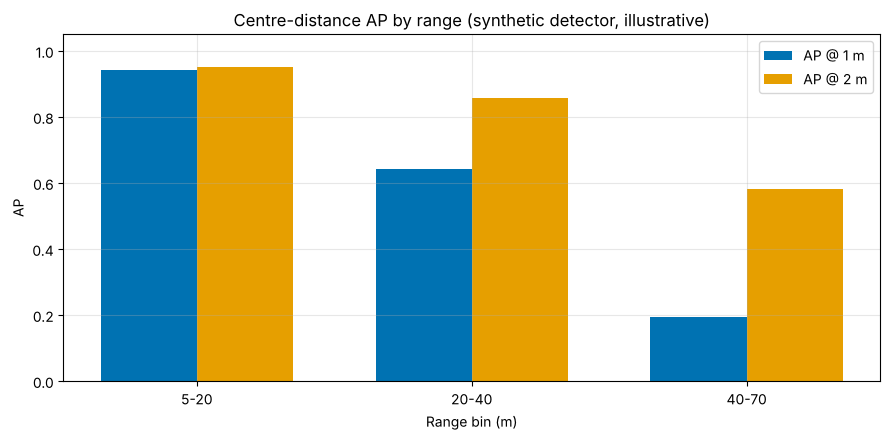

    5-20 m: AP@1m 0.943, AP@2m 0.952, mean centre error 0.36 m
   20-40 m: AP@1m 0.643, AP@2m 0.858, mean centre error 0.53 m
   40-70 m: AP@1m 0.193, AP@2m 0.583, mean centre error 0.61 m
AP@1m falls from 0.94 (near) to 0.19 (far): a single mAP hides this range dependence, which is exactly what a safety argument needs (cf. stopping distance in notebook 05).


In [16]:
bins = [(5, 20), (20, 40), (40, 70)]
rows = []
for lo, hi in bins:
    g_sub = [g for g in gts if lo <= g[2] < hi]
    d_sub = [d for d in dets if lo <= np.linalg.norm(d[1]) < hi]
    ap1, e1 = ap_centre_distance(g_sub, d_sub, 1.0)
    ap2, _ = ap_centre_distance(g_sub, d_sub, 2.0)
    rows.append({'range (m)': f'{lo}-{hi}', 'GT objects': len(g_sub), 'AP@1m': round(ap1, 3), 'AP@2m': round(ap2, 3),
                 'mean centre error (m)': round(e1, 2)})
rdf = pd.DataFrame(rows); display(rdf)
fig, ax = plt.subplots(figsize=(9, 4.5))
xx = np.arange(len(rdf)); w = 0.35
ax.bar(xx - w / 2, rdf['AP@1m'], w, label='AP @ 1 m', color=OKABE_ITO[4])
ax.bar(xx + w / 2, rdf['AP@2m'], w, label='AP @ 2 m', color=OKABE_ITO[0])
ax.set_xticks(xx); ax.set_xticklabels(rdf['range (m)']); ax.set_xlabel('Range bin (m)'); ax.set_ylabel('AP')
ax.set_ylim(0, 1.05); ax.set_title('Centre-distance AP by range (synthetic detector, illustrative)'); ax.legend()
plt.tight_layout(); plt.show()
for r in rows:
    print(f"  {r['range (m)']:>6} m: AP@1m {r['AP@1m']:.3f}, AP@2m {r['AP@2m']:.3f}, mean centre error {r['mean centre error (m)']} m")
print(f"AP@1m falls from {rows[0]['AP@1m']:.2f} (near) to {rows[-1]['AP@1m']:.2f} (far): a single mAP hides this range dependence,"
      " which is exactly what a safety argument needs (cf. stopping distance in notebook 05).")

---
## Safety perspective

- **ISO/PAS 8800:2024** treats data as a safety-relevant work product: datasets need specified requirements (coverage of the ODD and of the input space, label quality, independence of training, validation and test data) and verification against those requirements.
- **ISO 21448:2022:** cells of the ODD that the data does not cover are conditions whose effect on the function is unknown; coverage analysis against an ODD description (ISO 34503:2023) is how they are found and moved into the analysed space.
- **Metrics:** a single mAP or NDS hides class, distance and condition dependence; the analysis above shows that the "hard" part of the distribution is often not evaluated at all.

Continue with: [09 Trajectory prediction](09_trajectory_prediction.ipynb) · [02_Failures_and_Robustness/02 — Corner cases](../02_Failures_and_Robustness/02_corner_cases.ipynb) · [04_SOTIF_ISO21448/04 — Simulation-based validation](../04_SOTIF_ISO21448/04_simulation_based_validation.ipynb) · [06_AI_Safety_ISO_PAS_8800/01 — AI safety standards](../06_AI_Safety_ISO_PAS_8800/01_ai_safety_standards.ipynb).

---
## In industry

**Work product:** the *dataset specification* and *dataset verification report* for an ML perception component (ISO/PAS 8800 data life cycle), with a link to the SOTIF triggering-condition analysis (ISO 21448) and the ODD description (ISO 34503).

**Who:** the perception data lead or ML engineer writes it; the safety engineer (SOTIF / AI safety) reviews it against the hazard analysis; data acquisition and labelling teams implement it.

A specification entry looks like this (illustrative values):

| ID | Requirement | Derived from | Verification |
|---|---|---|---|
| DS-07 | Test set contains ≥ 300 independent pedestrian tracks at 30–50 m, per light condition (day, dusk, night) | AEB pedestrian KPI (notebook 05), SG-02 | Count by metadata query; independence by track/drive ID |
| DS-12 | Label policy defines minimum box height and occlusion levels; ≥ 98 % agreement on a double-labelled audit sample | Label-quality requirement | Inter-annotator audit |
| DS-15 | No drive appears in both training and test data | Independence requirement | Split by drive ID, automated check |
| DS-21 | Licence of every source permits the intended (commercial) use | Legal / provenance | Provenance register |

**What reviewers and assessors look for**

- [ ] Every safety-relevant class × distance × condition cell has a count, and a stated minimum (with its statistical rationale)
- [ ] Gaps are either filled, covered by an ODD restriction, or carried as an open SOTIF triggering condition — never silently ignored
- [ ] Ignored / DontCare policies are documented, because they decide what the metrics can see
- [ ] Training/test independence is by drive or location, not by random frame split
- [ ] Synthetic data (e.g. CARLA) is labelled as such, with an argument about its validity
- [ ] Licence and provenance are recorded for every dataset and every pretrained model

## Key takeaways

- Scenes, sensor frames, keyframes and boxes are different units; box counts overstate diversity because one object appears in many frames.
- KITTI's 40,570 labelled training objects are 71 % cars; pedestrians, cyclists and seated persons together are about 16 %; `Person_sitting` has only 222 labels.
- Pedestrians shrink below KITTI's 25 px evaluation limit at roughly 50 m; distant, occluded and truncated objects are partly or completely outside the benchmark.
- KITTI has no night, rain or snow and no child or wheelchair labels; several safety-relevant cells hold fewer than the 299 instances needed for even a zero-failure recall-0.99 claim.
- nuScenes (1.4 M 3D boxes) and Waymo Open (12.6 M) are far larger and include night and rain, but are also non-commercial; ZOD (CC BY-SA 4.0) and SOTIF-PCOD (CC BY 4.0) are among the few with permissive licences.
- Labels are not independent samples: the same cyclist appears in up to dozens of KITTI frames, so test/train splits and sample-size arguments must work with recordings or tracks, not frames.
- A dataset specification — classes, conditions, distance bands, counts, independence, label policy, licence — is the ISO/PAS 8800 work product that makes these gaps visible and reviewable.

## Self-assessment

1. nuScenes reports 1.4 M 3D boxes in 40 k keyframes. Why is "1.4 M" not the number of different objects?
2. From the analysis above, roughly what share of KITTI pedestrians lies beyond 40 m, and why does the benchmark evaluate even fewer of them?
3. How many independent instances are needed to claim recall ≥ 0.999 at 95 % confidence with zero misses? What happens to the requirement if one miss is observed?
4. Why does a high KITTI AP say nothing about pedestrians at night?
5. A supplier proposes to fine-tune a production pedestrian detector on Argoverse 2 and KITTI. What is your objection?
6. What does SOTIF-PCOD add compared with KITTI, and what new argument does it require?
7. Compute NDS for mAP = 0.40 and TP errors mATE 0.3 m, mASE 0.25, mAOE 0.5 rad, mAVE 0.8 m/s, mAAE 0.2.

<details>
<summary>Show answers</summary>

1. The same physical object is annotated in every keyframe in which it is visible (2 Hz over a 20 s scene), so one pedestrian can produce dozens of boxes.
2. A few per cent (the printed value above). Beyond about 50 m a pedestrian is shorter than 25 px and is "Ignored" by the benchmark; many more are in `DontCare` regions and are not labelled at all.
3. $n \ge \ln(0.05)/\ln(0.999) \approx 2{,}995$. With one observed miss the binomial bound needs about 4,700 instances (exact: solve $P(X \le 1) \le 0.05$).
4. KITTI contains no night frames: the metric is computed on a distribution that does not include the condition; the performance there is simply unknown (a SOTIF unknown).
5. Both datasets are non-commercial (CC BY-NC-SA); a product model must not be trained on them. In addition they do not cover the product's sensors or ODD.
6. Night and rain conditions with controlled variation and ground truth, under CC BY 4.0. It requires an argument that simulated LiDAR effects (noise, rain attenuation, reflectivity) are representative of the real sensor, and validation on real data.
7. Sum of (1 − min(1, mTP)) = 0.7 + 0.75 + 0.5 + 0.2 + 0.8 = 2.95; NDS = 0.1 × (5 × 0.40 + 2.95) = 0.495.

</details>

## References

1. Geiger, A., Lenz, P., Urtasun, R. (2012). Are we ready for autonomous driving? The KITTI vision benchmark suite. *CVPR*. https://doi.org/10.1109/CVPR.2012.6248074
2. Geiger, A., Lenz, P., Stiller, C., Urtasun, R. (2013). Vision meets robotics: The KITTI dataset. *International Journal of Robotics Research* 32(11). https://doi.org/10.1177/0278364913491297
3. Caesar, H. et al. (2020). nuScenes: A multimodal dataset for autonomous driving. *CVPR*. https://doi.org/10.1109/CVPR42600.2020.01164
4. Sun, P. et al. (2020). Scalability in perception for autonomous driving: Waymo Open Dataset. *CVPR*. https://doi.org/10.1109/CVPR42600.2020.00252 ; dataset figures: https://waymo.com/open/about/ (as of October 2026)
5. Wilson, B. et al. (2021). Argoverse 2: Next generation datasets for self-driving perception and forecasting. *NeurIPS Datasets and Benchmarks*. arXiv:2301.00493 ; licence: https://www.argoverse.org/about.html
6. Mao, J. et al. (2021). One million scenes for autonomous driving: ONCE dataset. *NeurIPS Datasets and Benchmarks*. arXiv:2106.11037 ; terms: https://once-for-auto-driving.github.io/terms_of_use.html
7. Alibeigi, M. et al. (2023). Zenseact Open Dataset: A large-scale and diverse multimodal dataset for autonomous driving. *ICCV*. arXiv:2305.02008
8. Patel, M. (2024). SOTIF PCOD [dataset]. IEEE DataPort. https://doi.org/10.21227/j43q-z578 (CC BY 4.0)
9. Patel, M., Jung, R. (2024). Simulation-based performance evaluation of 3D object detection methods with deep learning for a LiDAR point cloud dataset in a SOTIF-related use case. *VEHITS 2024*. https://doi.org/10.5220/0012707300003702
10. Patel, M., Jung, R., Khatun, M. (2025). A systematic literature review on safety of the intended functionality for automated driving systems. SAE Technical Paper 2025-01-5030. https://doi.org/10.4271/2025-01-5030
11. ISO/PAS 8800:2024. *Road vehicles — Safety and artificial intelligence.* https://www.iso.org/standard/83303.html
12. ISO 21448:2022. *Road vehicles — Safety of the intended functionality.* https://www.iso.org/standard/77490.html
13. ISO 34503:2023. *Road vehicles — Test scenarios for automated driving systems — Specification for operational design domain.* https://www.iso.org/standard/78952.html

---
**Navigation:** ← [07 Multi-object tracking](07_multi_object_tracking.ipynb) · [Module index](README.md) · [09 Trajectory prediction](09_trajectory_prediction.ipynb) →